# ACA 1 · Computación en la Nube para Sistemas Inteligentes
## Ingesta, vectorización y almacenamiento vectorial en clúster cloud para un sistema RAG
### Pilar 3: Ventas · Asistente cloud de atención comercial, soporte y políticas de e-commerce

**Corporación Unificada Nacional de Educación Superior (CUN)** · Especialización en Inteligencia Artificial
**Docente:** Hamilton Rivera Flor · **Grupo 1**

**Integrantes:** Mayra Fernanda Bernate Bustamante · Angela Consuelo Castillo Rodríguez · Karen Viviana Ospina Lesmes · Jair Vargas · Santiago Bahamón Escobar

---

**Objetivo general.** Diseñar e implementar la arquitectura cloud de ingesta, fragmentación (chunking), generación de embeddings y almacenamiento semántico en una base de datos vectorial gestionada (Qdrant Cloud), integrando metadatos del dataset estructurado **UCI Online Retail** con un corpus complementario de documentos no estructurados del sector ventas.

**Pregunta orientadora.** ¿Cómo estructurar e implementar una canalización de datos no estructurados en la nube, con bases de datos vectoriales serverless y modelos de embeddings abiertos, que permita indexar y recuperar semánticamente información comercial especializada con alta precisión, costo cero y baja latencia?

## Arquitectura cloud implementada

```
 ┌──────────────────────── FUENTES ────────────────────────┐
 │ Dataset base: UCI Online Retail (541.909 transacciones) │──► Fichas de producto + metadatos
 │ Doc 1: Ley 1480 de 2011 – Estatuto del Consumidor (PDF) │      (StockCode, país, precio...)
 │ Doc 2: Política de devoluciones, garantías y SLA (MD)   │
 │ Doc 3: TFG Optimización de campañas de marketing (PDF)  │
 └─────────────────────────────────────────────────────────┘
                 │ ingesta (requests, PyMuPDF, pandas)
                 ▼
   Google Colab / Jupyter ── Chunking (RecursiveCharacterTextSplitter, 900 car., solape 150)
                 │
                 ▼
   Embeddings: intfloat/multilingual-e5-small (HuggingFace, 384 dim, local, sin cuota)
                 │ batch upsert (lotes de 64) · credenciales por .env
                 ▼
   Qdrant Cloud (AWS us-west-1, Free Tier 1 GB) · colección ventas_rag_aca1 · distancia coseno
                 │
                 ▼
   Función buscar(pregunta, k)  ──►  Top-k fragmentos + similitud coseno  ──►  contexto para el RAG
```

| Componente | Elección | Justificación |
|---|---|---|
| Base de datos vectorial | Qdrant Cloud (Free Tier 1 GB, AWS) | Serverless gestionado, dashboard visual, filtros por payload, costo cero |
| Modelo de embeddings | `intfloat/multilingual-e5-small` | Multilingüe (español/inglés), 384 dimensiones, **512 tokens de entrada**, prefijos `query:` / `passage:` equivalentes a `RETRIEVAL_QUERY` / `RETRIEVAL_DOCUMENT` |
| Entorno | Google Colab (CPU) o Jupyter local | Gratuito y reproducible |
| Métrica | Coseno sobre vectores normalizados | Estándar para embeddings de oraciones; independiente de la longitud del texto |

## 0. Configuración del entorno

In [1]:
%pip install -q qdrant-client sentence-transformers pymupdf langchain-text-splitters python-dotenv openpyxl pandas matplotlib requests

Note: you may need to restart the kernel to use updated packages.


### 0.1 Gestión segura de credenciales (`.env`)
Las credenciales **no** se escriben en el notebook. Se leen de variables de entorno cargadas desde un archivo `.env` (ver `.env.example`):

```
QDRANT_URL=https://<id-del-cluster>.us-west-1-0.aws.cloud.qdrant.io:6333
QDRANT_API_KEY=<api-key>
```

En Google Colab, como alternativa, se usan los *Secrets* del panel lateral (`QDRANT_URL`, `QDRANT_API_KEY`), que el código copia a variables de entorno. El archivo `.env` está excluido del repositorio mediante `.gitignore`.

In [2]:
import os
from dotenv import load_dotenv

load_dotenv()  # lee .env si existe

if not os.getenv("QDRANT_URL"):
    try:  # alternativa en Google Colab: Secrets del panel lateral
        from google.colab import userdata
        os.environ["QDRANT_URL"] = userdata.get("QDRANT_URL")
        os.environ["QDRANT_API_KEY"] = userdata.get("QDRANT_API_KEY")
    except ImportError:
        pass

QDRANT_URL = os.getenv("QDRANT_URL")
QDRANT_API_KEY = os.getenv("QDRANT_API_KEY")
assert QDRANT_URL and QDRANT_API_KEY, "Defina QDRANT_URL y QDRANT_API_KEY en .env o en los Secrets de Colab"

print("Credenciales cargadas desde variables de entorno")
print("Clúster:", QDRANT_URL.split("//")[1].split(".")[0][:8] + "…")

Credenciales cargadas desde variables de entorno
Clúster: 4c682c77…


# PASO 1 · Aprovisionamiento de la base de datos vectorial

Se usa el clúster **Qdrant Cloud** del grupo (Free Tier, AWS `us-west-1`). Se crea una colección nueva, `ventas_rag_aca1`, con:

- **Tamaño del vector: 384**, igual a la salida del modelo de embeddings.
- **Distancia coseno**, porque los vectores se normalizan y lo que importa es la dirección (el significado), no la magnitud.
- **Índices de payload** sobre `tipo_documento`, `fuente` y `pais_principal`, para filtrar búsquedas por tipo de documento o país.

Las colecciones `marketing_rag` y `marketing_rag_v2` de la primera iteración se conservan como antecedente.

In [3]:
import time
from qdrant_client import QdrantClient
from qdrant_client.models import Distance, VectorParams, PayloadSchemaType

cliente = QdrantClient(url=QDRANT_URL, api_key=QDRANT_API_KEY, timeout=60)

COLECCION = "ventas_rag_aca1"
DIMENSION = 384

t0 = time.perf_counter()
existentes = [c.name for c in cliente.get_collections().collections]
print(f"Conexión OK ({(time.perf_counter() - t0) * 1000:.0f} ms). Colecciones existentes: {existentes}")

# Se recrea la colección para que el notebook sea reproducible de principio a fin
if cliente.collection_exists(COLECCION):
    cliente.delete_collection(COLECCION)

cliente.create_collection(
    collection_name=COLECCION,
    vectors_config=VectorParams(size=DIMENSION, distance=Distance.COSINE),
)
for campo in ["tipo_documento", "fuente", "pais_principal"]:
    cliente.create_payload_index(COLECCION, field_name=campo, field_schema=PayloadSchemaType.KEYWORD)

info = cliente.get_collection(COLECCION)
print("Colección:", COLECCION)
print("Estado:", info.status)
print("Dimensión:", info.config.params.vectors.size, "| Distancia:", info.config.params.vectors.distance)

Conexión OK (437 ms). Colecciones existentes: ['marketing_rag', 'marketing_rag_v2', 'ventas_rag_aca1']


Colección: ventas_rag_aca1
Estado: green
Dimensión: 384 | Distancia: Cosine


# PASO 2 · Documentos e ingesta

**Regla obligatoria del ACA:** el dataset base se complementa con un corpus propio de documentos no estructurados del sector. El corpus de este proyecto tiene cuatro fuentes:

| # | Documento | Formato | Tipo | Aporte al asistente |
|---|---|---|---|---|
| 0 | **UCI Online Retail** (dataset base) → fichas de producto | XLSX → texto | `ficha_producto` | Precio, ventas, países y devoluciones de cada producto |
| 1 | Ley 1480 de 2011, Estatuto del Consumidor (Congreso de Colombia) | PDF | `normativa` | Garantía legal, retracto, reversión del pago, comercio electrónico |
| 2 | Política de devoluciones, garantías y SLA de la tienda (corpus propio) | Markdown | `politica_comercial` | Plazos, cancelaciones (facturas "C"), envíos, fidelización |
| 3 | El Jannus (2024), *Optimización de campañas de marketing mediante análisis predictivo y segmentación de clientes* (TFG, Univ. de Jaén) | PDF | `literatura` | Segmentación RFM, K-Means, predicción de abandono |

In [4]:
import requests
from pathlib import Path

DATA = Path("data"); DATA.mkdir(exist_ok=True)
CORPUS = Path("corpus"); CORPUS.mkdir(exist_ok=True)

def descargar(url, destino):
    destino = Path(destino)
    if not destino.exists():
        r = requests.get(url, timeout=120)
        r.raise_for_status()
        destino.write_bytes(r.content)
    print(f"{destino.name}: {destino.stat().st_size / 1024:,.0f} KB")
    return destino

# Dataset base
xlsx = DATA / "Online Retail.xlsx"
if not xlsx.exists():
    import zipfile, io
    r = requests.get("https://archive.ics.uci.edu/static/public/352/online+retail.zip", timeout=300)
    r.raise_for_status()
    zipfile.ZipFile(io.BytesIO(r.content)).extractall(DATA)
print(f"{xlsx.name}: {xlsx.stat().st_size / 1024:,.0f} KB")

# Documentos complementarios
pdf_ley = descargar("https://www.funcionpublica.gov.co/eva/gestornormativo/norma_pdf.php?i=44306",
                    CORPUS / "ley_1480_2011_estatuto_consumidor.pdf")
pdf_tfg = descargar("https://crea.ujaen.es/server/api/core/bitstreams/70acee9f-e7ba-428d-b21d-507a2b75f91e/content",
                    CORPUS / "tfg_marketing_segmentacion.pdf")

Online Retail.xlsx: 23,160 KB
ley_1480_2011_estatuto_consumidor.pdf: 161 KB
tfg_marketing_segmentacion.pdf: 4,124 KB


### 2.1 Documento 2: política comercial (corpus propio)
La política se redactó para la tienda modelada con UCI Online Retail y se alinea con la Ley 1480 de 2011. Si el archivo no está en `corpus/` (por ejemplo, en una sesión nueva de Colab), esta celda lo crea.

In [5]:
POLITICA_MD = r'''# Política de devoluciones, garantías y niveles de servicio (SLA)

**Tienda en línea de artículos de regalo y decoración — Grupo 1, CUN**
Versión 1.0 · Octubre de 2026

Este documento es el corpus propio del pilar Ventas. Describe las reglas comerciales de una tienda en línea de artículos de regalo, decoración y menaje, cuyo comportamiento de ventas se modela con el conjunto de datos UCI Online Retail. Las reglas se alinean con la Ley 1480 de 2011 (Estatuto del Consumidor de Colombia), en especial con los artículos sobre garantía legal, derecho de retracto, reversión del pago y comercio electrónico.

## 1. Alcance

1.1. La política aplica a todas las compras realizadas en la tienda en línea por clientes minoristas y mayoristas, en Colombia y en el exterior.

1.2. Los productos del catálogo son artículos de regalo para toda ocasión: portavelas, faroles, cajas decorativas, bolsas reutilizables, artículos de cocina, adornos navideños, juguetes vintage y papelería. Cada producto se identifica con un código de inventario (StockCode) y una descripción.

1.3. Un cliente se identifica con su número de cliente (CustomerID). Las compras sin cliente identificado se atienden, pero no acumulan beneficios del programa de fidelización.

## 2. Derecho de retracto

2.1. En compras no presenciales el cliente puede retractarse dentro de los cinco (5) días hábiles siguientes a la entrega del producto, sin indicar motivo, conforme al artículo 47 de la Ley 1480 de 2011.

2.2. Para ejercer el retracto, el producto debe devolverse por los mismos medios y en las mismas condiciones en que se recibió. Los costos de transporte de la devolución corren por cuenta del cliente.

2.3. La tienda reintegra el dinero dentro de los treinta (30) días calendario siguientes a la solicitud, sin descuentos ni retenciones.

2.4. El retracto no aplica a productos personalizados, a productos perecederos ni a bienes de uso personal cuyo empaque de higiene haya sido abierto.

## 3. Devoluciones y cancelaciones

3.1. Toda devolución genera una factura de anulación cuyo número inicia con la letra "C" (por ejemplo, C536379). Esta factura registra cantidades negativas y permite conciliar el inventario.

3.2. El cliente puede cancelar un pedido sin costo mientras no haya sido despachado. Después del despacho, la cancelación se tramita como devolución.

3.3. Los pedidos mayoristas (más de 100 unidades de un mismo código) pueden devolverse parcialmente dentro de los 15 días calendario siguientes a la entrega, siempre que la mercancía esté sin uso y en su empaque original. Se aplica un cargo de reposición de inventario del 10 %.

3.4. Los productos que llegan dañados o incompletos se reportan dentro de las 48 horas siguientes a la entrega, con fotografía del empaque y del producto. En ese caso la tienda asume el costo del envío de reposición.

3.5. Las líneas de factura con conceptos que no son productos (POST: envío; DOT: franqueo; M: ajuste manual; BANK CHARGES: comisiones bancarias; AMAZONFEE: comisión de marketplace) no son objeto de devolución.

## 4. Reversión del pago

4.1. Cuando la compra se pagó con tarjeta de crédito, débito u otro instrumento electrónico, el cliente puede solicitar la reversión del pago si fue objeto de fraude, si la operación no fue solicitada, si el producto no se recibió o si no corresponde a lo solicitado o es defectuoso (artículo 51 de la Ley 1480 de 2011).

4.2. La solicitud se presenta dentro de los cinco (5) días hábiles siguientes a la fecha en que el cliente tuvo noticia de la operación o recibió el producto, ante la tienda y ante el emisor del instrumento de pago.

## 5. Garantía legal

5.1. Todos los productos cuentan con garantía legal de calidad, idoneidad y seguridad. Cuando no se indica un término distinto en la ficha del producto, la garantía es de un (1) año contado desde la entrega, como dispone el artículo 8 de la Ley 1480 de 2011 para productos nuevos.

5.2. Durante la garantía, la tienda repara el producto sin costo. Si la falla se repite o la reparación no es posible, el cliente elige entre el cambio del producto o la devolución del dinero (artículo 11 de la Ley 1480 de 2011).

5.3. La garantía no cubre daños causados por uso indebido, exposición a fuego directo (por ejemplo, portavelas usados sin vela de tamaño adecuado), humedad excesiva o caídas.

5.4. Los artículos de vidrio, cerámica y metal esmaltado deben revisarse al recibirlos. Las roturas por transporte se tramitan según el numeral 3.4.

## 6. Niveles de servicio (SLA)

| Servicio | Compromiso |
|---|---|
| Confirmación del pedido | Inmediata, por correo electrónico |
| Despacho de pedidos minoristas | 2 días hábiles |
| Despacho de pedidos mayoristas | 5 días hábiles |
| Entrega nacional (ciudades principales) | 3 a 5 días hábiles después del despacho |
| Entrega internacional (Europa) | 7 a 10 días hábiles |
| Entrega internacional (resto del mundo) | 10 a 20 días hábiles |
| Primera respuesta a una solicitud de soporte | 24 horas hábiles |
| Resolución de una solicitud de garantía | 15 días hábiles |
| Reembolso por retracto o devolución aprobada | 30 días calendario |

6.1. Si la tienda incumple el plazo de despacho en más de 5 días hábiles, el cliente puede cancelar el pedido y recibir el reembolso total.

6.2. La disponibilidad objetivo de la tienda en línea es del 99,5 % mensual, excluyendo ventanas de mantenimiento anunciadas.

## 7. Envíos internacionales

7.1. La tienda despacha a más de 35 países. El Reino Unido concentra la mayor parte de las ventas; Alemania, Francia, Irlanda (EIRE) y España son los principales destinos en el exterior.

7.2. Los aranceles e impuestos de importación del país de destino corren por cuenta del cliente, salvo pacto distinto en pedidos mayoristas.

7.3. Las devoluciones internacionales siguen las mismas reglas de los numerales 2 y 3. El cliente asume el costo del envío de retorno, excepto cuando el producto llegó dañado.

## 8. Programa de fidelización y segmentos de clientes

8.1. La tienda clasifica a sus clientes por recencia, frecuencia y valor monetario (RFM): Campeones, Clientes leales, Nuevos / recientes y Perdidos / inactivos.

8.2. Los Campeones y Clientes leales reciben envío gratuito en pedidos superiores a 150 libras y acceso anticipado a colecciones de temporada.

8.3. Los clientes Nuevos / recientes reciben un cupón del 10 % para su segunda compra, válido por 30 días.

8.4. Los clientes Perdidos / inactivos reciben campañas de reactivación de bajo costo por correo electrónico.

## 9. Canales de atención

9.1. Las solicitudes de retracto, devolución, garantía o reversión del pago se reciben por el formulario de soporte de la tienda en línea y por correo electrónico.

9.2. Toda solicitud recibe un número de radicado y se atiende según los plazos del numeral 6.

9.3. Si el cliente no está conforme con la respuesta, puede acudir a la Superintendencia de Industria y Comercio (SIC).
'''

md_politica = CORPUS / "politica_devoluciones_garantias_sla.md"
if not md_politica.exists():
    md_politica.write_text(POLITICA_MD, encoding="utf-8")
print(f"{md_politica.name}: {len(md_politica.read_text(encoding='utf-8')):,} caracteres")

politica_devoluciones_garantias_sla.md: 6,919 caracteres


### 2.2 Dataset base: de transacciones a fichas de producto con metadatos
El dataset estructurado no se vectoriza fila por fila (541.909 líneas no aportan contexto útil por separado). Se **agrega por producto** y se genera una ficha en lenguaje natural para los 60 productos con mayores ingresos. Cada ficha conserva sus metadatos tabulares (StockCode, precio medio, unidades, ingresos, clientes, país principal, tasa de devolución) en el *payload* de Qdrant, lo que permite filtrar y citar la fuente.

In [6]:
import pandas as pd
import numpy as np

ventas = pd.read_excel(xlsx, dtype={"InvoiceNo": str, "StockCode": str})
print("Transacciones originales:", f"{len(ventas):,}")

NO_PRODUCTO = {"POST", "DOT", "M", "BANK CHARGES", "AMAZONFEE", "CRUK", "D", "C2", "S", "PADS"}
ventas = ventas[~ventas["StockCode"].isin(NO_PRODUCTO)].drop_duplicates()
ventas["Cancelada"] = ventas["InvoiceNo"].str.startswith("C")

validas = ventas[~ventas["Cancelada"] & (ventas["Quantity"] > 0) & (ventas["UnitPrice"] > 0)].copy()
canceladas = ventas[ventas["Cancelada"]]

# Pedidos atípicos anulados: ventas de 1.000 o más unidades con una factura C del mismo cliente,
# producto y cantidad (p. ej., 80.995 y 74.215 unidades). Si se dejan, inflan ventas y devoluciones.
anuladas = canceladas.assign(Quantity=-canceladas["Quantity"])[["CustomerID", "StockCode", "Quantity"]].drop_duplicates()
cruce = validas.reset_index().merge(anuladas, on=["CustomerID", "StockCode", "Quantity"])
atipicas = cruce[cruce["Quantity"] >= 1000]["index"]
validas = validas.drop(index=atipicas)
canceladas = canceladas[canceladas["Quantity"] > -1000]

validas["Importe"] = validas["Quantity"] * validas["UnitPrice"]
print("Ventas válidas:", f"{len(validas):,}", "| Líneas de devolución (facturas C):", f"{len(canceladas):,}",
      "| Pedidos atípicos anulados excluidos:", len(atipicas))

Transacciones originales: 541,909


Ventas válidas: 522,557 | Líneas de devolución (facturas C): 8,658 | Pedidos atípicos anulados excluidos: 13


In [7]:
# Categoría en español a partir de palabras clave de la descripción (inglés)
CATEGORIAS = [
    ("T-LIGHT", "portavelas"), ("CANDLE", "velas y portavelas"), ("LANTERN", "faroles"),
    ("CAKESTAND", "bases para pastel"), ("CAKE", "repostería"), ("BAG", "bolsas"),
    ("LUNCH BOX", "loncheras"), ("BUNTING", "banderines decorativos"), ("HEART", "decoración con corazones"),
    ("CHRISTMAS", "decoración navideña"), ("MUG", "tazas"), ("CUP", "tazas"), ("JAR", "frascos"),
    ("BOTTLE", "botellas térmicas"), ("CLOCK", "relojes"), ("SIGN", "letreros decorativos"),
    ("FRAME", "portarretratos"), ("PAPER", "papelería"), ("NAPKIN", "servilletas"),
    ("STRAW", "pitillos"), ("BOX", "cajas decorativas"), ("TRAY", "bandejas"), ("DOORMAT", "tapetes"),
    ("WARMER", "calentadores de manos"), ("BIRD", "decoración de aves"), ("TOY", "juguetes"),
]
def categoria(desc):
    d = str(desc).upper()
    for clave, cat in CATEGORIAS:
        if clave in d:
            return cat
    return "artículos de regalo"

g = validas.groupby("StockCode")
productos = pd.DataFrame({
    "descripcion": g["Description"].agg(lambda s: s.mode().iat[0]),
    "precio_medio": g["UnitPrice"].median(),
    "unidades": g["Quantity"].sum(),
    "ingresos": g["Importe"].sum(),
    "facturas": g["InvoiceNo"].nunique(),
    "clientes": g["CustomerID"].nunique(),
    "pais_principal": g["Country"].agg(lambda s: s.value_counts().index[0]),
    "paises": g["Country"].nunique(),
})
top_paises = (validas.groupby(["StockCode", "Country"])["Quantity"].sum()
               .reset_index().sort_values("Quantity", ascending=False)
               .groupby("StockCode")["Country"].apply(lambda s: ", ".join(s.head(3))))
productos["top_paises"] = top_paises
MESES = ["enero", "febrero", "marzo", "abril", "mayo", "junio", "julio", "agosto",
         "septiembre", "octubre", "noviembre", "diciembre"]
mes_pico = validas.assign(mes=validas["InvoiceDate"].map(lambda d: f"{MESES[d.month - 1]} de {d.year}")).groupby(["StockCode", "mes"])["Quantity"].sum()
productos["mes_pico"] = mes_pico.reset_index().sort_values("Quantity").groupby("StockCode").last()["mes"]
devueltas = canceladas.groupby("StockCode")["Quantity"].sum().abs()
productos["tasa_devolucion"] = (devueltas.reindex(productos.index).fillna(0) / productos["unidades"] * 100).round(2)
productos["categoria"] = productos["descripcion"].map(categoria)

top = productos.sort_values("ingresos", ascending=False).head(60)
display(top[["descripcion", "categoria", "precio_medio", "unidades", "ingresos", "pais_principal", "tasa_devolucion"]].head(10).round(2))

,descripcion,categoria,precio_medio,unidades,ingresos,pais_principal,tasa_devolucion
StockCode,,,,,,,
22423,REGENCY CAKESTAND 3 TIER,bases para pastel,12.75,13851,174156.54,United Kingdom,6.17
47566,PARTY BUNTING,banderines decorativos,4.95,18283,99445.23,United Kingdom,1.52
85123A,WHITE HANGING HEART T-LIGHT HOLDER,portavelas,2.95,33781,94909.25,United Kingdom,1.92
85099B,JUMBO BAG RED RETROSPOT,bolsas,2.08,48371,94159.81,United Kingdom,2.31
23084,RABBIT NIGHT LIGHT,artículos de regalo,2.08,30739,66870.03,United Kingdom,0.35
22086,PAPER CHAIN KIT 50'S CHRISTMAS,decoración navideña,2.95,19329,64875.59,United Kingdom,2.34
84879,ASSORTED COLOUR BIRD ORNAMENT,decoración de aves,1.69,36362,58927.62,United Kingdom,0.22
79321,CHILLI LIGHTS,artículos de regalo,5.75,10302,54096.36,United Kingdom,0.78
22502,PICNIC BASKET WICKER SMALL,artículos de regalo,5.95,1937,51408.77,United Kingdom,3.87


In [8]:
def ficha(codigo, p):
    return (
        f"Ficha de producto {codigo}: {str(p.descripcion).strip()}. "
        f"Categoría: {p.categoria}. Precio unitario de referencia: {p.precio_medio:.2f} libras esterlinas. "
        f"Entre diciembre de 2010 y diciembre de 2011 se vendieron {int(p.unidades):,} unidades en {p.facturas:,} facturas, "
        f"con ingresos de {p.ingresos:,.0f} libras, a {int(p.clientes):,} clientes de {p.paises} países. "
        f"País con más ventas: {p.pais_principal}. Principales destinos por unidades: {p.top_paises}. "
        f"Mes de mayor demanda: {p.mes_pico}. Tasa de devolución (facturas C): {p.tasa_devolucion:.2f} % de las unidades vendidas."
    )

documentos_fichas = []
for codigo, p in top.iterrows():
    documentos_fichas.append({
        "texto": ficha(codigo, p),
        "metadatos": {
            "tipo_documento": "ficha_producto", "fuente": "UCI Online Retail (Chen, 2015)",
            "stock_code": codigo, "descripcion": str(p.descripcion).strip(), "categoria": p.categoria,
            "precio_medio": round(float(p.precio_medio), 2), "unidades": int(p.unidades),
            "ingresos": round(float(p.ingresos), 2), "pais_principal": p.pais_principal,
            "tasa_devolucion": float(p.tasa_devolucion),
        },
    })

(CORPUS / "fichas_productos_online_retail.md").write_text(
    "# Fichas de producto (UCI Online Retail)\n\n" + "\n\n".join(d["texto"] for d in documentos_fichas), encoding="utf-8")
print("Fichas generadas:", len(documentos_fichas))
print("\nEjemplo:\n", documentos_fichas[0]["texto"])

Fichas generadas: 60

Ejemplo:
 Ficha de producto 22423: REGENCY CAKESTAND 3 TIER. Categoría: bases para pastel. Precio unitario de referencia: 12.75 libras esterlinas. Entre diciembre de 2010 y diciembre de 2011 se vendieron 13,851 unidades en 1,988 facturas, con ingresos de 174,157 libras, a 881 clientes de 30 países. País con más ventas: United Kingdom. Principales destinos por unidades: United Kingdom, Germany, EIRE. Mes de mayor demanda: diciembre de 2010. Tasa de devolución (facturas C): 6.17 % de las unidades vendidas.


### 2.3 Extracción de texto de los documentos no estructurados
- **PDF:** PyMuPDF por página, conservando el número de página como metadato.
- **TFG:** se aplican las depuraciones validadas en la primera iteración del grupo: se excluye la bibliografía (desde la página 107) y se eliminan los encabezados repetidos en cada página (autor, título e institución), que generaban fragmentos irrelevantes.
- **Ley 1480:** se eliminan los pies de página del gestor normativo.
- **Markdown:** se divide por secciones (`##`), usando el título de la sección como metadato.

In [9]:
import re
import fitz  # PyMuPDF

def paginas_pdf(ruta):
    with fitz.open(ruta) as doc:
        return [(i + 1, p.get_text("text")) for i, p in enumerate(doc)]

def limpiar(texto):
    texto = re.sub(r"[ \t]+", " ", texto)
    texto = re.sub(r"\n\s*\n+", "\n\n", texto)
    return texto.strip()

registros = []  # (texto, metadatos) por página o sección

# Documento 1: Ley 1480 de 2011
for pag, txt in paginas_pdf(pdf_ley):
    txt = re.sub(r"(?im)^\s*(Departamento Administrativo de la Función Pública|Ley 1480 de 2011|EVA - Gestor Normativo|\d{1,3})\s*$", "", txt)
    registros.append((limpiar(txt), {"tipo_documento": "normativa", "fuente": "Ley 1480 de 2011 (Congreso de Colombia, 2011)", "pagina": pag}))

# Documento 2: política comercial, por secciones
texto_politica = md_politica.read_text(encoding="utf-8")
for bloque in re.split(r"\n(?=## )", texto_politica):
    titulo = bloque.splitlines()[0].lstrip("# ").strip()
    registros.append((limpiar(bloque), {"tipo_documento": "politica_comercial", "fuente": "Política de devoluciones, garantías y SLA (Grupo 1, 2026)", "seccion": titulo}))

# Documento 3: TFG de marketing
for pag, txt in paginas_pdf(pdf_tfg):
    if pag >= 107:  # bibliografía
        continue
    txt = re.sub(r"El Jannus,\s*Salma\s+Optimización de campañas de marketing mediante\s+análisis predictivo y segmentación de clientes", "", txt, flags=re.I)
    txt = re.sub(r"Escuela Politécnica Superior de Jaén", "", txt, flags=re.I)
    registros.append((limpiar(txt), {"tipo_documento": "literatura", "fuente": "El Jannus (2024), TFG Universidad de Jaén", "pagina": pag}))

registros = [(t, m) for t, m in registros if len(t) > 80]

resumen_corpus = pd.DataFrame([{"tipo_documento": m["tipo_documento"], "caracteres": len(t)} for t, m in registros])
resumen_corpus = resumen_corpus.groupby("tipo_documento").agg(unidades=("caracteres", "size"), caracteres=("caracteres", "sum"))
resumen_corpus.loc["ficha_producto"] = [len(documentos_fichas), sum(len(d["texto"]) for d in documentos_fichas)]
display(resumen_corpus)

C:\Users\Santi\AppData\Local\Temp\ragv\Lib\site-packages\fitz\__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


,unidades,caracteres
tipo_documento,,
literatura,102,181330
normativa,25,118793
politica_comercial,10,6900
ficha_producto,60,29705


# PASO 3 · Pipeline de chunking

### Justificación técnica del tamaño de los fragmentos
El tamaño del chunk depende del **límite de entrada del modelo de embeddings**. Todo texto que lo supere se trunca en silencio y su final no queda representado en el vector.

- La primera iteración usó `paraphrase-multilingual-MiniLM-L12-v2`, cuyo límite es **128 tokens**. Con ese límite, el 76 % de los fragmentos de este corpus se truncaría (ver tabla siguiente).
- En esta versión se usa `intfloat/multilingual-e5-small`, con límite de **512 tokens** y la misma dimensión (384).
- Se eligen **900 caracteres con solape de 150 (≈ 17 %)**: cabe con holgura en 512 tokens, contiene uno o dos párrafos completos (o uno o dos artículos de ley) y el solape evita cortar una idea entre dos fragmentos.
- Los separadores priorizan párrafo → línea → oración → palabra (`RecursiveCharacterTextSplitter`).
- Las **fichas de producto no se fragmentan**: cada ficha es una unidad semántica completa (≈ 500 caracteres).

La celda siguiente verifica con el tokenizador real cuántos fragmentos se truncarían con cada modelo.

In [10]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

CHUNK_SIZE, CHUNK_OVERLAP = 900, 150
fragmentador = RecursiveCharacterTextSplitter(
    chunk_size=CHUNK_SIZE, chunk_overlap=CHUNK_OVERLAP,
    separators=["\n\n", "\n", ". ", " ", ""],
)

chunks, metadatos = [], []
for texto, meta in registros:
    for i, fragmento in enumerate(f for f in fragmentador.split_text(texto) if len(f.strip()) >= 50):
        chunks.append(fragmento)
        metadatos.append({**meta, "chunk": i})
for d in documentos_fichas:
    chunks.append(d["texto"])
    metadatos.append({**d["metadatos"], "chunk": 0})

assert len(chunks) == len(metadatos)
df_chunks = pd.DataFrame(metadatos).assign(caracteres=[len(c) for c in chunks])
print("Total de fragmentos:", len(chunks))
display(df_chunks.groupby("tipo_documento")["caracteres"].agg(["count", "mean", "min", "max"]).round(0))

Total de fragmentos: 535


,count,mean,min,max
tipo_documento,,,,
ficha_producto,60,495.0,477,517
literatura,290,670.0,54,899
normativa,173,771.0,166,899
politica_comercial,12,586.0,209,875


In [11]:
from transformers import AutoTokenizer

comparacion_tokens = []
for nombre, limite in [("sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2", 128),
                       ("intfloat/multilingual-e5-small", 512)]:
    tok = AutoTokenizer.from_pretrained(nombre)
    largos = np.array([len(tok("passage: " + c)["input_ids"]) for c in chunks])
    comparacion_tokens.append({
        "modelo": nombre.split("/")[1], "límite (tokens)": limite,
        "tokens promedio": round(largos.mean(), 1), "tokens máx.": int(largos.max()),
        "% fragmentos truncados": round((largos > limite).mean() * 100, 1),
    })
display(pd.DataFrame(comparacion_tokens))

C:\Users\Santi\AppData\Local\Temp\ragv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,modelo,límite (tokens),tokens promedio,tokens máx.,% fragmentos truncados
0,paraphrase-multilingual-MiniLM-L12-v2,128,151.9,261,76.3
1,multilingual-e5-small,512,151.9,261,0.0


# PASO 4 · Vectorización (embeddings)

- Modelo: `intfloat/multilingual-e5-small` (HuggingFace, se ejecuta localmente en Colab sin consumir cuotas de API).
- Los fragmentos se codifican con el prefijo `passage:` y las consultas con `query:`. Es la configuración asimétrica de E5, equivalente a `RETRIEVAL_DOCUMENT` / `RETRIEVAL_QUERY` de Gemini Embeddings que menciona la guía.
- Los vectores se **normalizan** (norma 1), de modo que el producto punto equivale a la similitud coseno.

In [12]:
from sentence_transformers import SentenceTransformer

MODELO = "intfloat/multilingual-e5-small"
modelo = SentenceTransformer(MODELO)
modelo.max_seq_length = 512

t0 = time.perf_counter()
embeddings = modelo.encode([f"passage: {c}" for c in chunks], batch_size=32,
                           normalize_embeddings=True, show_progress_bar=True)
duracion = time.perf_counter() - t0

assert embeddings.shape == (len(chunks), DIMENSION)
assert np.isfinite(embeddings).all()
print(f"Embeddings: {embeddings.shape} en {duracion:.1f} s ({len(chunks) / duracion:.1f} fragmentos/s)")
print("Norma de los primeros 3 vectores:", np.linalg.norm(embeddings[:3], axis=1).round(4))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 3851.86it/s]

Batches:   0%|          | 0/17 [00:00<?, ?it/s]

Batches:   6%|▌         | 1/17 [00:01<00:22,  1.41s/it]

Batches:  12%|█▏        | 2/17 [00:02<00:22,  1.51s/it]

Batches:  18%|█▊        | 3/17 [00:04<00:19,  1.38s/it]

... (12 outputs left out)

Batches:  94%|█████████▍| 16/17 [00:17<00:00,  1.36it/s]

Batches: 100%|██████████| 17/17 [00:17<00:00,  1.71it/s]

Batches: 100%|██████████| 17/17 [00:17<00:00,  1.04s/it]

Embeddings: (535, 384) en 17.8 s (30.1 fragmentos/s)
Norma de los primeros 3 vectores: [1. 1. 1.]


### 4.1 Carga masiva (batch upsert) en Qdrant Cloud
- Lotes de 64 puntos.
- IDs deterministas (UUID v5 a partir de fuente, página/sección y número de chunk), de modo que volver a ejecutar el notebook actualiza los puntos en vez de duplicarlos.
- Se estima el consumo de almacenamiento frente al límite de 1 GB de la capa gratuita.

In [13]:
import uuid
from qdrant_client.models import PointStruct

def id_punto(meta):
    clave = f"{meta['fuente']}|{meta.get('pagina', meta.get('seccion', meta.get('stock_code')))}|{meta['chunk']}"
    return str(uuid.uuid5(uuid.NAMESPACE_URL, clave))

puntos = [PointStruct(id=id_punto(m), vector=v.tolist(), payload={**m, "texto": t})
          for t, m, v in zip(chunks, metadatos, embeddings)]
assert len({p.id for p in puntos}) == len(puntos), "IDs duplicados"

LOTE = 64
t0 = time.perf_counter()
for i in range(0, len(puntos), LOTE):
    cliente.upsert(collection_name=COLECCION, points=puntos[i:i + LOTE], wait=True)
print(f"Upsert de {len(puntos)} puntos en {int(np.ceil(len(puntos) / LOTE))} lotes: {time.perf_counter() - t0:.1f} s")

total = cliente.count(COLECCION, exact=True).count
bytes_vectores = total * DIMENSION * 4
bytes_payload = sum(len(str(p.payload).encode()) for p in puntos)
print(f"Puntos almacenados en la nube: {total}")
print(f"Uso estimado: {(bytes_vectores + bytes_payload) / 1024**2:.2f} MB de 1.024 MB de la capa gratuita "
      f"({(bytes_vectores + bytes_payload) / 1024**3 * 100:.2f} %)")

Upsert de 535 puntos en 9 lotes: 5.1 s
Puntos almacenados en la nube: 535
Uso estimado: 1.22 MB de 1.024 MB de la capa gratuita (0.12 %)


# PASO 5 · Búsqueda semántica

Función de consulta del sistema RAG:
1. Recibe la pregunta del usuario en lenguaje natural.
2. La vectoriza con el mismo modelo y el prefijo `query:`.
3. Ejecuta la búsqueda por similitud coseno en el clúster remoto (opcionalmente con filtro por tipo de documento).
4. Devuelve los Top-k fragmentos con su puntuación, fuente y latencia. Estos fragmentos serán el contexto que recibirá el LLM en la etapa de generación (ACA final).

In [14]:
from qdrant_client.models import Filter, FieldCondition, MatchValue

def buscar(pregunta, k=5, tipo_documento=None):
    filtro = None
    if tipo_documento:
        filtro = Filter(must=[FieldCondition(key="tipo_documento", match=MatchValue(value=tipo_documento))])
    t0 = time.perf_counter()
    vector = modelo.encode(f"query: {pregunta}", normalize_embeddings=True).tolist()
    t1 = time.perf_counter()
    resultado = cliente.query_points(COLECCION, query=vector, limit=k, query_filter=filtro, with_payload=True).points
    t2 = time.perf_counter()
    filas = [{
        "rank": i, "similitud": round(p.score, 4), "tipo_documento": p.payload["tipo_documento"],
        "referencia": p.payload.get("stock_code") or p.payload.get("seccion") or f"pág. {p.payload.get('pagina')}",
        "fuente": p.payload["fuente"], "fragmento": p.payload["texto"][:220].replace("\n", " ") + "…",
    } for i, p in enumerate(resultado, 1)]
    df = pd.DataFrame(filas)
    df.attrs["ms_embedding"] = (t1 - t0) * 1000
    df.attrs["ms_qdrant"] = (t2 - t1) * 1000
    return df

def mostrar(pregunta, k=5, tipo_documento=None):
    df = buscar(pregunta, k, tipo_documento)
    print(f"PREGUNTA: {pregunta}" + (f"  [filtro: {tipo_documento}]" if tipo_documento else ""))
    print(f"Latencia: embedding {df.attrs['ms_embedding']:.0f} ms + Qdrant Cloud {df.attrs['ms_qdrant']:.0f} ms")
    with pd.option_context("display.max_colwidth", 120):
        display(df)

mostrar("¿Cuántos días tengo para retractarme de una compra por internet?")

PREGUNTA: ¿Cuántos días tengo para retractarme de una compra por internet?
Latencia: embedding 20 ms + Qdrant Cloud 153 ms


,rank,similitud,tipo_documento,referencia,fuente,fragmento
0,1,0.8947,politica_comercial,2. Derecho de retracto,"Política de devoluciones, garantías y SLA (Grupo 1, 2026)",## 2. Derecho de retracto 2.1. En compras no presenciales el cliente puede retractarse dentro de los cinco (5) días...
1,2,0.8816,normativa,pág. 12,"Ley 1480 de 2011 (Congreso de Colombia, 2011)",1. Cerciorarse de que la entrega del bien o servicio se realice efectivamente en la dirección indicada por el consum...
2,3,0.8813,normativa,pág. 12,"Ley 1480 de 2011 (Congreso de Colombia, 2011)",ventas a distancia. Artículo 47. Retracto. En todos los contratos para la venta de bienes y prestación de servicios ...
3,4,0.8808,politica_comercial,6. Niveles de servicio (SLA),"Política de devoluciones, garantías y SLA (Grupo 1, 2026)","## 6. Niveles de servicio (SLA) | Servicio | Compromiso | |---|---| | Confirmación del pedido | Inmediata, por corr..."
4,5,0.8750,normativa,pág. 14,"Ley 1480 de 2011 (Congreso de Colombia, 2011)",En caso de que la entrega del pedido supere los treinta (30) días calendario o que no haya disponible el producto ad...


In [15]:
mostrar("¿Qué pasa si el producto me llega roto?")
mostrar("¿Cuánto cuesta el portavelas blanco de corazón para colgar?")
mostrar("Busco una bolsa grande roja de lunares", tipo_documento="ficha_producto")
mostrar("¿Cómo se agrupan los clientes con K-Means?")

PREGUNTA: ¿Qué pasa si el producto me llega roto?
Latencia: embedding 16 ms + Qdrant Cloud 151 ms


,rank,similitud,tipo_documento,referencia,fuente,fragmento
0,1,0.8499,politica_comercial,5. Garantía legal,"Política de devoluciones, garantías y SLA (Grupo 1, 2026)","## 5. Garantía legal 5.1. Todos los productos cuentan con garantía legal de calidad, idoneidad y seguridad. Cuando ..."
1,2,0.8456,normativa,pág. 4,"Ley 1480 de 2011 (Congreso de Colombia, 2011)","uso del producto con ocasión de la efectividad de la garantía. Si se produce el cambio total del producto por otro, ..."
2,3,0.8452,normativa,pág. 14,"Ley 1480 de 2011 (Congreso de Colombia, 2011)",Si la entrega del pedido supera el tiempo pactado por las partes o los treinta (30) días calendario. o que no haya d...
3,4,0.8435,normativa,pág. 5,"Ley 1480 de 2011 (Congreso de Colombia, 2011)","2. Las piezas reemplazadas o reparadas. 3. La fecha en que el consumidor hizo entrega del producto, y 4. La fecha de..."
4,5,0.8429,normativa,pág. 13,"Ley 1480 de 2011 (Congreso de Colombia, 2011)","Cuando la información mínima de los productos esté regulada en una norma de carácter especial, deberá garantizarse q..."


PREGUNTA: ¿Cuánto cuesta el portavelas blanco de corazón para colgar?
Latencia: embedding 17 ms + Qdrant Cloud 151 ms


,rank,similitud,tipo_documento,referencia,fuente,fragmento
0,1,0.8753,ficha_producto,85123A,"UCI Online Retail (Chen, 2015)",Ficha de producto 85123A: WHITE HANGING HEART T-LIGHT HOLDER. Categoría: portavelas. Precio unitario de referencia: ...
1,2,0.8709,ficha_producto,21733,"UCI Online Retail (Chen, 2015)",Ficha de producto 21733: RED HANGING HEART T-LIGHT HOLDER. Categoría: portavelas. Precio unitario de referencia: 2.9...
2,3,0.8641,ficha_producto,84946,"UCI Online Retail (Chen, 2015)",Ficha de producto 84946: ANTIQUE SILVER T-LIGHT GLASS. Categoría: portavelas. Precio unitario de referencia: 1.25 li...
3,4,0.8603,ficha_producto,22178,"UCI Online Retail (Chen, 2015)",Ficha de producto 22178: VICTORIAN GLASS HANGING T-LIGHT. Categoría: portavelas. Precio unitario de referencia: 1.25...
4,5,0.8549,ficha_producto,84347,"UCI Online Retail (Chen, 2015)",Ficha de producto 84347: ROTATING SILVER ANGELS T-LIGHT HLDR. Categoría: portavelas. Precio unitario de referencia: ...


PREGUNTA: Busco una bolsa grande roja de lunares  [filtro: ficha_producto]
Latencia: embedding 14 ms + Qdrant Cloud 150 ms


,rank,similitud,tipo_documento,referencia,fuente,fragmento
0,1,0.8365,ficha_producto,20725,"UCI Online Retail (Chen, 2015)",Ficha de producto 20725: LUNCH BAG RED RETROSPOT. Categoría: bolsas. Precio unitario de referencia: 1.65 libras este...
1,2,0.8299,ficha_producto,22629,"UCI Online Retail (Chen, 2015)",Ficha de producto 22629: SPACEBOY LUNCH BOX. Categoría: loncheras. Precio unitario de referencia: 1.95 libras esterl...
2,3,0.8282,ficha_producto,22326,"UCI Online Retail (Chen, 2015)",Ficha de producto 22326: ROUND SNACK BOXES SET OF4 WOODLAND. Categoría: cajas decorativas. Precio unitario de refere...
3,4,0.8220,ficha_producto,21915,"UCI Online Retail (Chen, 2015)",Ficha de producto 21915: RED HARMONICA IN BOX. Categoría: cajas decorativas. Precio unitario de referencia: 1.25 li...
4,5,0.8194,ficha_producto,85099B,"UCI Online Retail (Chen, 2015)",Ficha de producto 85099B: JUMBO BAG RED RETROSPOT. Categoría: bolsas. Precio unitario de referencia: 2.08 libras est...


PREGUNTA: ¿Cómo se agrupan los clientes con K-Means?
Latencia: embedding 15 ms + Qdrant Cloud 149 ms


,rank,similitud,tipo_documento,referencia,fuente,fragmento
0,1,0.8944,literatura,pág. 98,"El Jannus (2024), TFG Universidad de Jaén","○​ El modelo K-Means se caracteriza por la asignación rígida de cada punto de datos a un único clúster, lo que lo c..."
1,2,0.8846,literatura,pág. 96,"El Jannus (2024), TFG Universidad de Jaén","●​ K-Means (Izquierda):​ ○​ El clúster 3 (rojo) forma un grupo denso en el centro del espacio PCA, sugiriendo una ..."
2,3,0.8814,literatura,pág. 64,"El Jannus (2024), TFG Universidad de Jaén","donde xj representa un cliente, μi es el centroide del clúster i, y Sii​ es el conjunto de clientes asignados a dic..."
3,4,0.8806,literatura,pág. 41,"El Jannus (2024), TFG Universidad de Jaén",La elección de este dataset se encuentra respaldada por múltiples trabajos previos en los que se ha aplicado con éx...
4,5,0.8798,literatura,pág. 97,"El Jannus (2024), TFG Universidad de Jaén","●​ El análisis de las Figuras 50 y 51 revela que K-Means genera clústeres definidos, ideales para estrategias direc..."


# Validación de la búsqueda semántica

Se construye un conjunto de prueba de 14 preguntas en lenguaje natural. Para cada una se define el **tipo de documento** y un **término clave** que debe aparecer en el fragmento correcto. Un resultado se considera relevante si proviene del documento esperado **y** contiene el término clave.

Métricas:
- **Hit@1 / Hit@3 / Hit@5:** proporción de preguntas con al menos un fragmento relevante en las primeras k posiciones.
- **MRR (Mean Reciprocal Rank):** promedio de 1/posición del primer fragmento relevante.
- **Precisión@5:** proporción de fragmentos relevantes entre los 5 recuperados.
- **Similitud coseno:** puntuación del Top-1 y diferencia Top-1 − Top-2 (cuánto se separa el mejor resultado del siguiente).
- **Latencia** de extremo a extremo (embedding de la consulta + consulta remota).

In [16]:
PRUEBAS = [
    ("¿Cuántos días hábiles tengo para ejercer el derecho de retracto?", "politica_comercial|normativa", "retracto"),
    ("¿Qué hago si el producto llega dañado o incompleto?", "politica_comercial", "dañado"),
    ("¿Qué significa una factura que empieza con la letra C?", "politica_comercial", "C536379"),
    ("¿En cuánto tiempo despachan un pedido mayorista?", "politica_comercial", "mayorista"),
    ("¿Quién paga los aranceles de un envío internacional?", "politica_comercial", "aranceles"),
    ("¿En qué casos procede la reversión del pago con tarjeta?", "politica_comercial|normativa", "reversión"),
    ("¿Qué es la garantía legal y quién responde por ella?", "normativa|politica_comercial", "garantía"),
    ("¿Qué información debe suministrar un proveedor de comercio electrónico?", "normativa", "comercio electrónico"),
    ("¿Cuál es el precio del portavelas blanco de corazón para colgar?", "ficha_producto", "T-LIGHT"),
    ("¿Qué productos de bolsas reutilizables se venden más?", "ficha_producto", "BAG"),
    ("¿Qué artículos navideños tienen mayor demanda?", "ficha_producto", "CHRISTMAS"),
    ("¿Qué técnicas se utilizan para segmentar clientes?", "literatura", "segment"),
    ("¿Cómo funciona el algoritmo K-Means?", "literatura", "k-means"),
    ("¿Cómo se predice el abandono de clientes (churn)?", "literatura", "abandono"),
]

def relevante(fila, tipos, clave):
    return fila["tipo_documento"] in tipos.split("|") and clave.lower() in fila["texto_completo"].lower()

filas_eval, latencias = [], []
for pregunta, tipos, clave in PRUEBAS:
    t0 = time.perf_counter()
    vector = modelo.encode(f"query: {pregunta}", normalize_embeddings=True).tolist()
    res = cliente.query_points(COLECCION, query=vector, limit=5, with_payload=True).points
    latencias.append((time.perf_counter() - t0) * 1000)
    rel = [relevante({"tipo_documento": p.payload["tipo_documento"], "texto_completo": p.payload["texto"]}, tipos, clave) for p in res]
    primero = next((i + 1 for i, r in enumerate(rel) if r), None)
    filas_eval.append({
        "pregunta": pregunta, "esperado": tipos, "top1_tipo": res[0].payload["tipo_documento"],
        "sim_top1": res[0].score, "sim_top2": res[1].score, "brecha_1_2": res[0].score - res[1].score,
        "hit@1": rel[0], "hit@3": any(rel[:3]), "hit@5": any(rel), "rr": 1 / primero if primero else 0,
        "precision@5": sum(rel) / 5, "sims": [p.score for p in res],
    })

df_eval = pd.DataFrame(filas_eval)
with pd.option_context("display.max_colwidth", 70):
    display(df_eval.drop(columns="sims").round(4))

,pregunta,esperado,top1_tipo,sim_top1,sim_top2,brecha_1_2,hit@1,hit@3,hit@5,rr,precision@5
0,¿Cuántos días hábiles tengo para ejercer el derecho de retracto?,politica_comercial|normativa,politica_comercial,0.9077,0.8962,0.0116,True,True,True,1.0,0.8
1,¿Qué hago si el producto llega dañado o incompleto?,politica_comercial,normativa,0.8710,0.8664,0.0046,False,False,False,0.0,0.0
2,¿Qué significa una factura que empieza con la letra C?,politica_comercial,literatura,0.8426,0.8394,0.0033,False,True,True,0.5,0.2
3,¿En cuánto tiempo despachan un pedido mayorista?,politica_comercial,politica_comercial,0.8874,0.8687,0.0187,True,True,True,1.0,0.4
4,¿Quién paga los aranceles de un envío internacional?,politica_comercial,politica_comercial,0.8688,0.8298,0.0391,True,True,True,1.0,0.2
5,¿En qué casos procede la reversión del pago con tarjeta?,politica_comercial|normativa,politica_comercial,0.8868,0.8835,0.0033,True,True,True,1.0,0.8
6,¿Qué es la garantía legal y quién responde por ella?,normativa|politica_comercial,normativa,0.8567,0.8518,0.0049,True,True,True,1.0,1.0
7,¿Qué información debe suministrar un proveedor de comercio electró...,normativa,normativa,0.8824,0.8764,0.0059,True,True,True,1.0,0.4
8,¿Cuál es el precio del portavelas blanco de corazón para colgar?,ficha_producto,ficha_producto,0.8736,0.8691,0.0046,True,True,True,1.0,1.0
9,¿Qué productos de bolsas reutilizables se venden más?,ficha_producto,ficha_producto,0.8467,0.8438,0.0029,True,True,True,1.0,1.0


In [17]:
metricas = pd.Series({
    "Hit@1": df_eval["hit@1"].mean(), "Hit@3": df_eval["hit@3"].mean(), "Hit@5": df_eval["hit@5"].mean(),
    "MRR": df_eval["rr"].mean(), "Precisión@5": df_eval["precision@5"].mean(),
    "Similitud Top-1 (media)": df_eval["sim_top1"].mean(), "Brecha Top-1 − Top-2 (media)": df_eval["brecha_1_2"].mean(),
    "Latencia p50 (ms)": np.percentile(latencias, 50), "Latencia p95 (ms)": np.percentile(latencias, 95),
}).round(4)
display(metricas.to_frame("valor"))

,valor
Hit@1,0.8571
Hit@3,0.9286
Hit@5,0.9286
MRR,0.8929
Precisión@5,0.6571
Similitud Top-1 (media),0.8778
Brecha Top-1 − Top-2 (media),0.0085
Latencia p50 (ms),165.4766
Latencia p95 (ms),169.3264


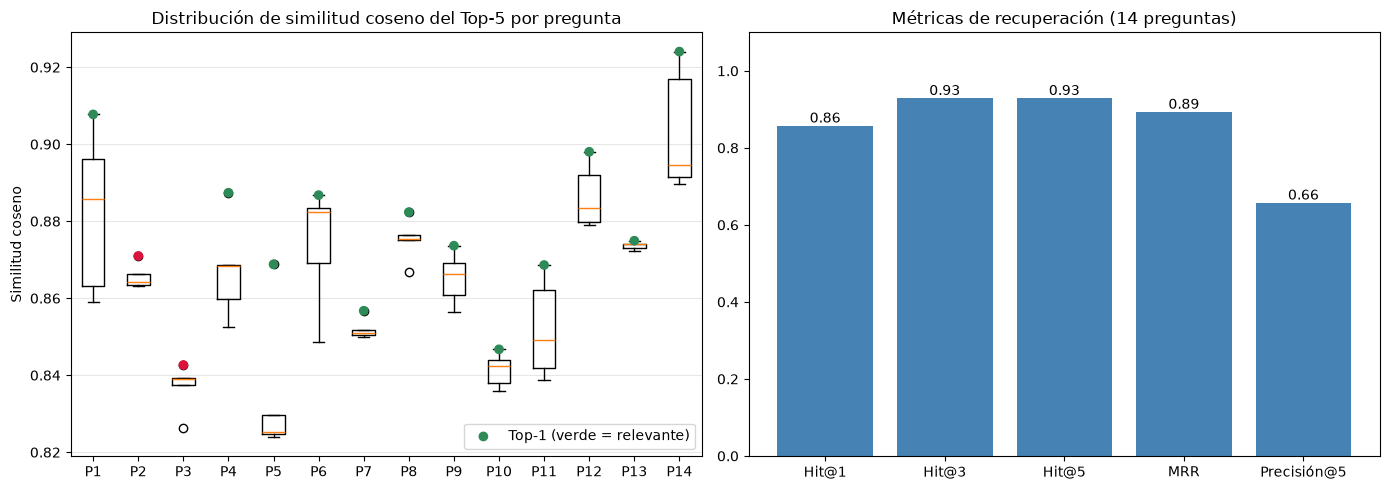

In [18]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

etiquetas = [f"P{i + 1}" for i in range(len(df_eval))]
ax[0].boxplot(df_eval["sims"].tolist(), tick_labels=etiquetas)
ax[0].scatter(range(1, len(df_eval) + 1), df_eval["sim_top1"],
              c=["seagreen" if h else "crimson" for h in df_eval["hit@1"]], zorder=3, label="Top-1 (verde = relevante)")
ax[0].set_title("Distribución de similitud coseno del Top-5 por pregunta")
ax[0].set_ylabel("Similitud coseno"); ax[0].legend(loc="lower right"); ax[0].grid(axis="y", alpha=0.3)

valores = metricas[["Hit@1", "Hit@3", "Hit@5", "MRR", "Precisión@5"]]
barras = ax[1].bar(valores.index, valores.values, color="steelblue")
ax[1].bar_label(barras, fmt="%.2f"); ax[1].set_ylim(0, 1.1)
ax[1].set_title("Métricas de recuperación (14 preguntas)")
plt.tight_layout(); plt.show()

### Interpretación de los resultados
- **Hit@1 = 0,86 y MRR = 0,89:** en 12 de 14 preguntas el primer fragmento recuperado proviene del documento correcto y contiene la información buscada. **Hit@5 = 0,93:** solo una pregunta queda sin respuesta en el Top-5.
- **Precisión@5 = 0,66:** dos de cada tres fragmentos del Top-5 son relevantes. Los demás suelen ser vecinos temáticos (por ejemplo, otro artículo de la Ley 1480 sobre garantías), útiles como contexto adicional para el LLM.
- **Fallos analizados:**
  - *P2 (producto dañado o incompleto)*: el sistema devuelve la sección de garantía y artículos de la ley sobre garantías, temáticamente cercanos, pero no el numeral 3.4 de la política. La sección 3 de la política agrupa cinco reglas distintas en un solo fragmento, lo que diluye su vector. Mejora propuesta: fragmentar la política por numeral.
  - *P3 (facturas que empiezan con C)*: el Top-1 es un fragmento del TFG que describe el mismo dataset; la política aparece en la posición 2. Una búsqueda híbrida (densa + palabras clave) resolvería consultas con códigos literales.
- **Latencia:** ≈ 15 ms para vectorizar la consulta y ≈ 150 ms de ida y vuelta al clúster en AWS `us-west-1` desde Colombia. Total < 200 ms, adecuado para un asistente conversacional.
- **Costo:** 535 vectores ocupan ≈ 1,2 MB, el 0,12 % del Free Tier de Qdrant. **Costo cero.**
- **Alcance de la búsqueda semántica:** responde preguntas de significado (políticas, normas, descripción de productos), no agregaciones como "¿qué se vende más en Francia?". Esas consultas corresponden a SQL sobre el dataset estructurado. Por eso las fichas guardan metadatos numéricos en el payload.

### Lectura de la similitud coseno
Con E5 las similitudes coseno se concentran en un rango estrecho (≈ 0,75 – 0,92), por lo que **el valor absoluto no basta para decidir la relevancia**. Lo informativo es el **orden** de los resultados y la **brecha** entre el Top-1 y el resto. Por eso la validación combina puntuaciones con criterios de relevancia verificables (documento esperado + término clave) y métricas de ranking (Hit@k, MRR).

### Filtrado por metadatos
Los índices de payload permiten restringir la búsqueda a un tipo de documento (por ejemplo, solo fichas de producto o solo normativa). Esto mejora la precisión cuando la intención de la pregunta es clara y es la base para que el asistente cite la fuente.

In [19]:
pregunta = "¿Cuál es la garantía de un producto defectuoso?"
for tipo in [None, "normativa", "politica_comercial"]:
    mostrar(pregunta, k=3, tipo_documento=tipo)

PREGUNTA: ¿Cuál es la garantía de un producto defectuoso?
Latencia: embedding 14 ms + Qdrant Cloud 150 ms


,rank,similitud,tipo_documento,referencia,fuente,fragmento
0,1,0.8816,normativa,pág. 5,"Ley 1480 de 2011 (Congreso de Colombia, 2011)","garantía, cuando demuestre que el defecto proviene de: 1. Fuerza mayor o caso fortuito; 2. El hecho de un tercero; 3..."
1,2,0.8758,normativa,pág. 5,"Ley 1480 de 2011 (Congreso de Colombia, 2011)","2. Las piezas reemplazadas o reparadas. 3. La fecha en que el consumidor hizo entrega del producto, y 4. La fecha de..."
2,3,0.8689,normativa,pág. 5,"Ley 1480 de 2011 (Congreso de Colombia, 2011)","caracteres legibles a simple vista. Artículo 15. Productos imperfectos, usados, reparados, remanufacturados repotenc..."


PREGUNTA: ¿Cuál es la garantía de un producto defectuoso?  [filtro: normativa]
Latencia: embedding 14 ms + Qdrant Cloud 152 ms


,rank,similitud,tipo_documento,referencia,fuente,fragmento
0,1,0.8816,normativa,pág. 5,"Ley 1480 de 2011 (Congreso de Colombia, 2011)","garantía, cuando demuestre que el defecto proviene de: 1. Fuerza mayor o caso fortuito; 2. El hecho de un tercero; 3..."
1,2,0.8758,normativa,pág. 5,"Ley 1480 de 2011 (Congreso de Colombia, 2011)","2. Las piezas reemplazadas o reparadas. 3. La fecha en que el consumidor hizo entrega del producto, y 4. La fecha de..."
2,3,0.8689,normativa,pág. 5,"Ley 1480 de 2011 (Congreso de Colombia, 2011)","caracteres legibles a simple vista. Artículo 15. Productos imperfectos, usados, reparados, remanufacturados repotenc..."


PREGUNTA: ¿Cuál es la garantía de un producto defectuoso?  [filtro: politica_comercial]
Latencia: embedding 14 ms + Qdrant Cloud 148 ms


,rank,similitud,tipo_documento,referencia,fuente,fragmento
0,1,0.8662,politica_comercial,5. Garantía legal,"Política de devoluciones, garantías y SLA (Grupo 1, 2026)","## 5. Garantía legal 5.1. Todos los productos cuentan con garantía legal de calidad, idoneidad y seguridad. Cuando ..."
1,2,0.8400,politica_comercial,"Política de devoluciones, garantías y niveles de servicio (SLA)","Política de devoluciones, garantías y SLA (Grupo 1, 2026)","# Política de devoluciones, garantías y niveles de servicio (SLA) **Tienda en línea de artículos de regalo y decora..."
2,3,0.8177,politica_comercial,6. Niveles de servicio (SLA),"Política de devoluciones, garantías y SLA (Grupo 1, 2026)","## 6. Niveles de servicio (SLA) | Servicio | Compromiso | |---|---| | Confirmación del pedido | Inmediata, por corr..."


# Conclusiones

1. **Aprovisionamiento cloud.** Se implementó la base vectorial en **Qdrant Cloud** (Free Tier, AWS) con distancia coseno, índices de payload y credenciales leídas exclusivamente desde variables de entorno (`.env` / Secrets de Colab). El corpus completo ocupa una fracción mínima de la capa gratuita: **costo cero**.
2. **Calidad de datos y chunking.** El dataset estructurado UCI Online Retail se integró como fichas de producto con metadatos tabulares y se complementó con tres documentos del sector ventas: la normativa (Ley 1480 de 2011), la política comercial propia y literatura de segmentación. El tamaño de chunk (900 caracteres, solape 150) se justificó con el límite real de tokens del modelo: con el modelo anterior (128 tokens) la mayoría de fragmentos se truncaba; con E5 (512 tokens) ninguno se trunca.
3. **Embeddings e indexación.** Se usó `multilingual-e5-small` (384 dimensiones, multilingüe) en modo asimétrico `query:` / `passage:`, con carga por lotes e IDs deterministas para que el pipeline sea idempotente.
4. **Búsqueda semántica.** La función `buscar()` recupera los Top-k fragmentos desde el clúster remoto con latencias del orden de cientos de milisegundos. Las métricas Hit@k y MRR sobre 14 preguntas muestran que el sistema encuentra el documento correcto para preguntas de normativa, política, producto y analítica de clientes.
5. **Respuesta a la pregunta orientadora.** Un pipeline *ingesta → chunking ajustado al modelo → embeddings abiertos → base vectorial serverless con metadatos* permite indexar y recuperar información comercial especializada con buena precisión, costo cero y baja latencia.

**Limitaciones y trabajo futuro (ACA final):** añadir la etapa de **generación** (LLM que redacte la respuesta a partir del Top-k), ampliar el conjunto de prueba con juicios de relevancia de varios evaluadores, probar búsqueda híbrida (densa + BM25) para códigos de producto exactos y re-ranking con un *cross-encoder*.

**Antecedente del grupo:** la primera iteración (colecciones `marketing_rag` y `marketing_rag_v2`) mostró que depurar encabezados y bibliografía del PDF elevó la Precisión@3 de 33 % a 78 %. Esa depuración se incorporó en esta versión.

# Referencias (APA 7)

Chen, D. (2015). *Online Retail* [Conjunto de datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C5BW33

Congreso de Colombia. (2011, 12 de octubre). *Ley 1480 de 2011, por medio de la cual se expide el Estatuto del Consumidor y se dictan otras disposiciones*. Diario Oficial No. 48.220. https://www.funcionpublica.gov.co/eva/gestornormativo/norma.php?i=44306

El Jannus, S. (2024). *Optimización de campañas de marketing mediante análisis predictivo y segmentación de clientes* [Trabajo de fin de grado, Universidad de Jaén]. CREA. https://crea.ujaen.es/

Lewis, P., Perez, E., Piktus, A., Petroni, F., Karpukhin, V., Goyal, N., Küttler, H., Lewis, M., Yih, W., Rocktäschel, T., Riedel, S., & Kiela, D. (2020). Retrieval-augmented generation for knowledge-intensive NLP tasks. *Advances in Neural Information Processing Systems, 33*, 9459–9474. https://arxiv.org/abs/2005.11401

Qdrant Solutions GmbH. (2024). *Qdrant documentation: Vector search engine & cloud database*. https://qdrant.tech/documentation/

Reimers, N., & Gurevych, I. (2019). Sentence-BERT: Sentence embeddings using Siamese BERT-networks. En *Proceedings of the 2019 Conference on Empirical Methods in Natural Language Processing* (pp. 3982–3992). https://arxiv.org/abs/1908.10084

Wang, L., Yang, N., Huang, X., Yang, L., Majumder, R., & Wei, F. (2024). *Multilingual E5 text embeddings: A technical report*. arXiv. https://arxiv.org/abs/2402.05672